# Демо 1. Ембединги й семантичний пошук

У цьому ноутбуці перетворюємо тексти на **ембединги**. Ембединги — це вектори, у які перетворюються тексти таким чином, що близькі за значенням тексти мають вектори близькі за розміщенням у векторному просторі. На базі цієї властивості будуємо семантичний пошук. З метою навчання робимо це без жодних спеціалізованих бібліотек,
використовуємо лише `numpy`.

Документи для пошуку — нормативні документи Житомирської політехніки з [docs.ztu.edu.ua](https://docs.ztu.edu.ua/):
положення про оцінювання, гуртожитки, стипендії, старосту академічної групи тощо.
Мовна модель, яка потім буде використовуватися для генерації, швидше за все не бачила цих документів під час тренування, тому відповісти на питання про них
вона зможе лише тоді, коли потрібний фрагмент документа буде знайдено й передано їй у промпті.
Пошук потрібних фрагментів документа і є першою половиною RAG.

_Зверніть увагу: ноутбук працює і на CPU, але з GPU ембединги рахуються швидше._

In [1]:
# sentence-transformers — бібліотека для обчислення ембедингів текстів, pypdf — витягування тексту з PDF
!pip install -q "sentence-transformers>=5" pypdf

In [2]:
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")

Пристрій: cuda


## 1. Модель ембедингів

Для перетворення текстових фрагментів на ембединги використовують спеціальні ембедингові моделі. [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) — багатомовна модель ембедингів із сімʼї моделей Qwen3. Вона перетворює текст довжиною до ~32 тис. токенів на вектор
із 1024 чисел. Ці два числа: максимальний розмір вхідного тексту і розмірність результуючого ембедингу - є важливими характеристиками ембедингових моделей.

In [3]:
EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
dtype = torch.float16 if device == "cuda" else torch.float32
model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device, model_kwargs={"dtype": dtype})

print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")
print(f"Максимальна довжина тексту в токенах: {model.max_seq_length}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Розмірність ембедингу: 1024
Максимальна довжина тексту в токенах: 32768


/tmp/ipykernel_1316/1793327947.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")


## 2. Ембединг одного речення

Незалежно від довжини тексту модель повертає вектор однакової розмірності.
Параметр `normalize_embeddings=True` ділить вектор на його евклідову ($L_{2}$) норму. Формула евклідової норми:

$$
\|\vec{x}\|_{2} = \sqrt{\sum_{i=1}^{n}x_{i}^{2}}
$$


Таким чином довжина (норма) вектора дорівнює 1.
Так косинусна подібність, яку потім потрібно часто підраховувати, зводиться до скалярного добутку.

In [4]:
sentence = "Чому я такий розумний?"
embedding = model.encode(sentence, normalize_embeddings=True)

print(f"Форма: {embedding.shape}")
print(f"Перші 8 чисел: {embedding[:8]}")
print(f"Евклідова норма вектора: {np.linalg.norm(embedding):.4f}")

# Загалом модель сама нормалізує вектор всередині,
# тому `normalize_embeddings=True` є зайвим у цьому конкретному випадку
# зверніть увагу на останній шар моделі
print(model)

Форма: (1024,)
Перші 8 чисел: [-0.02551   -0.09235   -0.0002925  0.02061    0.007275   0.0573
 -0.0488     0.04395  ]
Евклідова норма вектора: 1.0000
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'Qwen3Model'})
  (1): Pooling({'embedding_dimension': 1024, 'pooling_mode': 'lasttoken', 'include_prompt': True})
  (2): Normalize({})
)


## 3. Косинусна подібність

Близькість двох ембедингів вимірюють **косинусом кута** між ними:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Значення `1` означає однаковий напрям векторів, `0` — ортогональні вектори, `-1` - вектори вказують у повністю протилежні сторони.
Для нормалізованих векторів знаменник дорівнює 1, і косинус дорівнює скалярному добутку.
Порахуємо його вручну й порівняємо з вбудованим методом `model.similarity`.

In [5]:
a, b, c = model.encode(
    ["Скільки коштує проживання в гуртожитку?",
     "Яка плата за місце в студентському гуртожитку?",
     "Чому Політехніка краще за Гарвард?"],
    normalize_embeddings=True,
)

manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
with_library = model.similarity(a, b).item()

print(f"Вручну (a <=> b):     {manual:.4f}")
print(f"Бібліотека (a <=> b): {with_library:.4f}")

print(f"Бібліотека (a <=> c): {model.similarity(a, c).item():.4f}")

Вручну (a <=> b):     0.6489
Бібліотека (a <=> b): 0.6489
Бібліотека (a <=> c): 0.2329


In [6]:
# Оскільки, як зазначалося вище, ембединги є зазвичай нормалізованими векторами, то знаменник дорівнює `1`.
# Перевіримо це:
print(f"Норма a: {np.linalg.norm(a):.4f}")
print(f"Норма b: {np.linalg.norm(b):.4f}")
print(f"Норма c: {np.linalg.norm(c):.4f}")

Норма a: 1.0000
Норма b: 1.0000
Норма c: 1.0000


In [7]:
# Зважаючи на це ми можемо опускати нижню частину формули косинусної подібності
# і вираховувати її лише як скалярний добуток двох векторів

pure_dot_product = np.dot(a, b)
vector_norm_product = np.linalg.norm(a) * np.linalg.norm(b)

assert round(pure_dot_product, 4) == round(manual, 4) == round(with_library, 4), "The teacher made a mistake!"
assert np.isclose(vector_norm_product, 1), "The teacher doesn't know math"

### Косинусна подібність на простих векторах

Ембединг має 1024 виміри, але формула однакова для будь-якої розмірності.
Розглянемо її на двовимірних векторах, які можна намалювати. Вектор $a = (3, 1)$ порівнюємо з чотирма іншими:
- $e = (6, 2)$ — той самий напрям, але вдвічі довший;
- $b = (2, 2)$ — близький напрям;
- $c = (-1, 3)$ — перпендикулярний напрям;
- $d = (-3, -1)$ — протилежний напрям.

a·e =   20   ‖a‖·‖e‖ = 20.00   cos =  1.00   кут =   0.0°
a·b =    8   ‖a‖·‖b‖ =  8.94   cos =  0.89   кут =  26.6°
a·c =    0   ‖a‖·‖c‖ = 10.00   cos =  0.00   кут =  90.0°
a·d =  -10   ‖a‖·‖d‖ = 10.00   cos = -1.00   кут = 180.0°


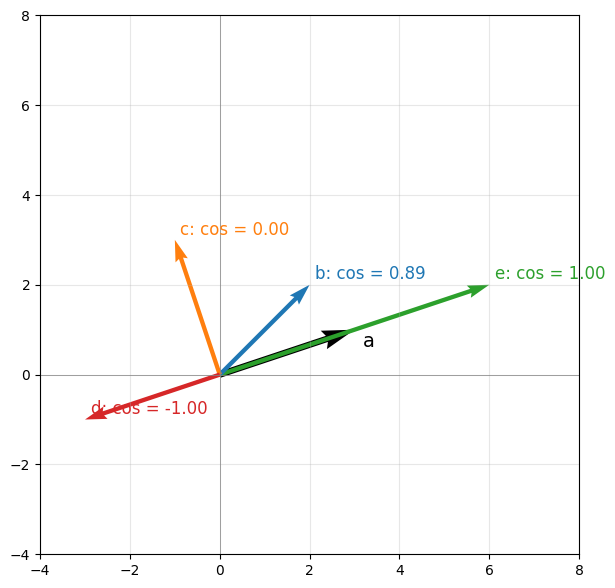

In [8]:
a2 = np.array([3, 1])
others = {
    "e": np.array([6, 2]),
    "b": np.array([2, 2]),
    "c": np.array([-1, 3]),
    "d": np.array([-3, -1]),
}


def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


for name, v in others.items():
    dot = np.dot(a2, v)
    norms = np.linalg.norm(a2) * np.linalg.norm(v)
    angle = np.degrees(np.arccos(np.clip(cosine(a2, v), -1, 1)))
    print(f"a·{name} = {dot:4}   ‖a‖·‖{name}‖ = {norms:5.2f}   cos = {dot / norms:5.2f}   кут = {angle:5.1f}°")

fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, *a2, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(f"{name}: cos = {cosine(a2, v):.2f}", v, xytext=(4, 4), textcoords="offset points",
                fontsize=12, color=color)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Косинус залежить лише від кута між векторами, а не від їхньої довжини: вектор $e$ удвічі довший за $a$,
але косинус дорівнює 1. Знаменник формули саме й прибирає вплив довжини.

Тепер нормалізуємо всі вектори — поділимо кожен на його довжину. Кінці нормалізованих векторів лежать
на колі радіуса 1, напрями не змінюються, а скалярний добуток дорівнює косинусу без жодного ділення.

e = [0.949 0.316]   довжина = 1.00   скалярний добуток =  1.00   cos =  1.00
b = [0.707 0.707]   довжина = 1.00   скалярний добуток =  0.89   cos =  0.89
c = [-0.316  0.949]   довжина = 1.00   скалярний добуток =  0.00   cos =  0.00
d = [-0.949 -0.316]   довжина = 1.00   скалярний добуток = -1.00   cos = -1.00


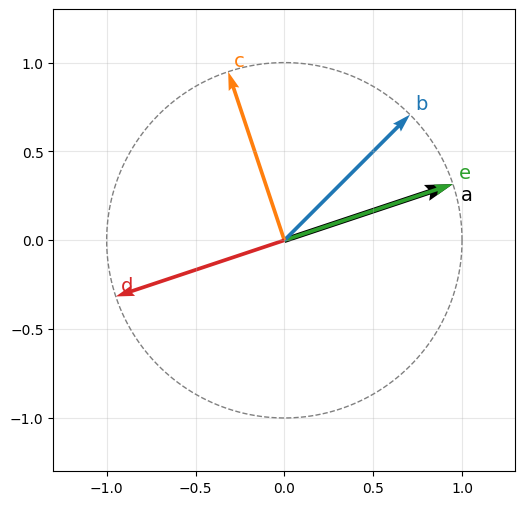

In [9]:
def normalize(v):
    return v / np.linalg.norm(v)


a2_unit = normalize(a2)
for name, v in others.items():
    v_unit = normalize(v)
    print(f"{name} = {np.round(v_unit, 3)}   довжина = {np.linalg.norm(v_unit):.2f}   "
          f"скалярний добуток = {np.dot(a2_unit, v_unit):5.2f}   cos = {cosine(a2, v):5.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color="grey", lw=1, ls="--")
ax.quiver(0, 0, *a2_unit, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2_unit, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    v_unit = normalize(v)
    ax.quiver(0, 0, *v_unit, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(name, v_unit, xytext=(4, 4), textcoords="offset points", fontsize=14, color=color)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Вектори $a$ і $e$ після нормалізації збіглися: однаковий напрям — однаковий нормалізований вектор.

### Три виміри

У трьох вимірах усе так само: кожна компонента вектора — окрема вісь, скалярний добуток — сума
трьох попарних добутків. Нехай компоненти означають, наскільки текст стосується трьох тем:
гуртожитку, стипендії й погоди.

«плата за гуртожиток» і «заселення в гуртожиток»: a·b = 0.9·0.8 + 0.3·0.1 + 0.0·0.1 = 0.75, cos = 0.97
«плата за гуртожиток» і «стипендія»: a·b = 0.9·0.2 + 0.3·0.9 + 0.0·0.0 = 0.45, cos = 0.51
«плата за гуртожиток» і «погода»: a·b = 0.9·0.0 + 0.3·0.1 + 0.0·0.9 = 0.03, cos = 0.03


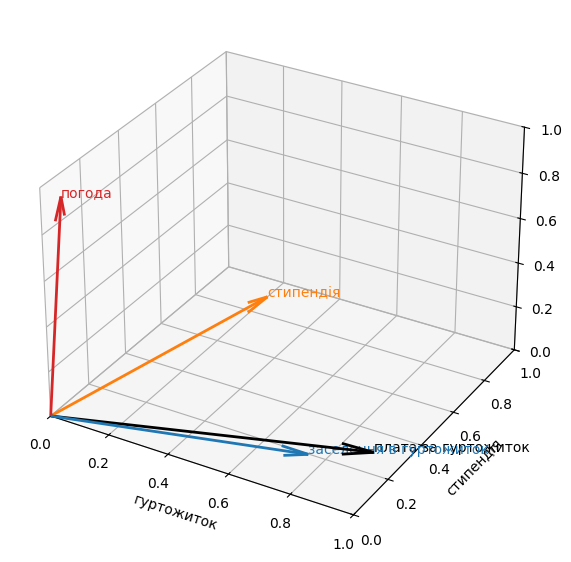

In [10]:
vectors_3d = {
    "плата за гуртожиток": np.array([0.9, 0.3, 0.0]),
    "заселення в гуртожиток": np.array([0.8, 0.1, 0.1]),
    "стипендія": np.array([0.2, 0.9, 0.0]),
    "погода": np.array([0.0, 0.1, 0.9]),
}
names_3d = list(vectors_3d)
query_3d = vectors_3d[names_3d[0]]
for name in names_3d[1:]:
    v = vectors_3d[name]
    products = " + ".join(f"{x:.1f}·{y:.1f}" for x, y in zip(query_3d, v))
    print(f"«{names_3d[0]}» і «{name}»: a·b = {products} = {np.dot(query_3d, v):.2f}, cos = {cosine(query_3d, v):.2f}")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
for (name, v), color in zip(vectors_3d.items(), ["black", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, 0, *v, color=color, arrow_length_ratio=0.1, linewidth=2)
    ax.text(*v, name, color=color, fontsize=10)
ax.set_xlabel("гуртожиток")
ax.set_ylabel("стипендія")
ax.set_zlabel("погода")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)
plt.show()

Справжній ембединг влаштований так само, лише замість трьох осей — 1024. На відміну від цього прикладу,
окремі виміри ембединга не мають зрозумілого людині змісту: значення має лише напрям вектора в цілому.

## 4. Матриця подібності

Порахуємо подібність кожного речення з кожним. Серед речень є:
- дві пари перефразувань (про плату за гуртожиток і про стипендію);
- два речення зі спільним словом «ключ», але різним змістом;
- речення, не повʼязане з рештою.

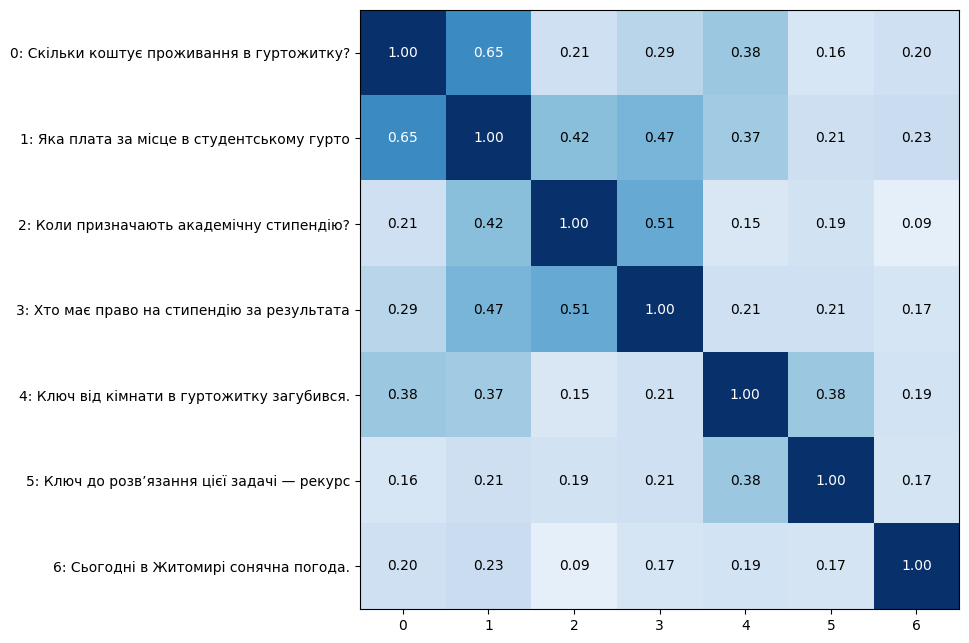

In [11]:
def show_similarity_matrix(sentences, figsize=(9, 7)):
  embeddings = model.encode(sentences, normalize_embeddings=True)
  similarity = embeddings @ embeddings.T

  fig, ax = plt.subplots(figsize=figsize)
  ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(len(sentences)), [f"{i}" for i in range(len(sentences))])
  ax.set_yticks(range(len(sentences)), [f"{i}: {s[:40]}" for i, s in enumerate(sentences)])
  for i in range(len(sentences)):
      for j in range(len(sentences)):
          ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                  color="white" if similarity[i, j] > 0.6 else "black")
  plt.tight_layout()
  plt.show()

uni_sentences = [
    "Скільки коштує проживання в гуртожитку?",
    "Яка плата за місце в студентському гуртожитку?",
    "Коли призначають академічну стипендію?",
    "Хто має право на стипендію за результатами сесії?",
    "Ключ від кімнати в гуртожитку загубився.",
    "Ключ до розвʼязання цієї задачі — рекурсія.",
    "Сьогодні в Житомирі сонячна погода.",
]

show_similarity_matrix(uni_sentences)


Перефразування мають найвищу подібність, хоча містять лише одне спільне слово, так само як і пара з речень 4-5, схожість яких вдвічі менша.
Водночас подібність ніколи не падає до нуля: навіть речення про погоду має з рештою додатну подібність.

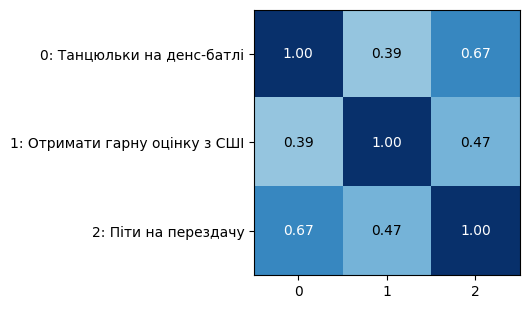

In [12]:
# Пограємося, вимірюючи подібність цілком випадкових і взагалі не придуманих викладачем фраз

pseudo_random_sentences = [
    "Танцюльки на денс-батлі",
    "Отримати гарну оцінку з СШІ",
    "Піти на перездачу"
]

show_similarity_matrix(pseudo_random_sentences, figsize=(5, 4))


## 5. Тексти на площині

Вектор із 1024 чисел неможливо намалювати, тому проєктуємо ембединги на площину методом головних компонент (Principal Component Analysis, PCA).
Проєкція втрачає більшу частину інформації, але групи речень на одну тему видно й на ній.

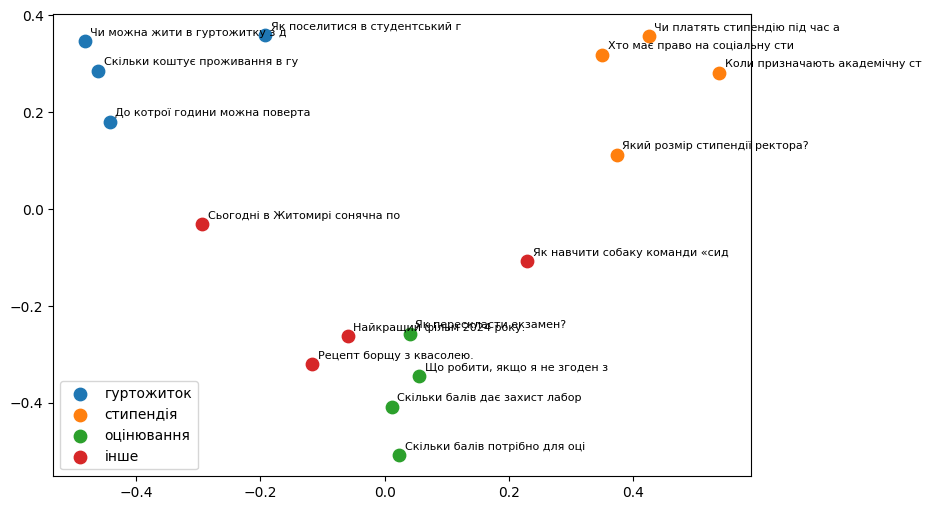

In [13]:
topics = {
    "гуртожиток": [
        "Скільки коштує проживання в гуртожитку?",
        "Як поселитися в студентський гуртожиток?",
        "До котрої години можна повертатися в гуртожиток?",
        "Чи можна жити в гуртожитку з дружиною?",
    ],
    "стипендія": [
        "Коли призначають академічну стипендію?",
        "Хто має право на соціальну стипендію?",
        "Який розмір стипендії ректора?",
        "Чи платять стипендію під час академічної відпустки?",
    ],
    "оцінювання": [
        "Скільки балів потрібно для оцінки «відмінно»?",
        "Що робити, якщо я не згоден з оцінкою?",
        "Як перескласти екзамен?",
        "Скільки балів дає захист лабораторної роботи?",
    ],
    "інше": [
        "Сьогодні в Житомирі сонячна погода.",
        "Рецепт борщу з квасолею.",
        "Найкращий фільм 2024 року.",
        "Як навчити собаку команди «сидіти»?",
    ],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
# На GPU модель працює у float16, а SVD у numpy підтримує лише float32 і float64
points = model.encode(texts, normalize_embeddings=True).astype(np.float32)

centered = points - points.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(9, 6))
for name in topics:
    mask = np.array(labels) == name
    ax.scatter(xy[mask, 0], xy[mask, 1], s=80, label=name)
for (x, y), t in zip(xy, texts):
    ax.annotate(t[:30], (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend()
plt.show()

## 6. Запит і документ кодуються по-різному

Короткий запит («до якої дати платити?») і фрагмент документа, що містить відповідь, — тексти різного вигляду.
Тому багато моделей ембедингів додають до запиту інструкцію. Qwen3-Embedding зберігає її у промпті `query`,
а документи кодує без інструкції.

In [14]:
print(repr(model.prompts["query"]))
print(repr(model.prompts["document"]))

'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'
''


In [15]:
passages = [
    "Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого.",
    "З 23:00 години і до 7:00 години в гуртожитку повинна додержуватись тиша.",
    "Вибори старости академічної групи на 1 курсі відбуваються після двох тижнів навчального процесу.",
    "Оцінка «добре» (B за шкалою ЄКТС) відповідає 82–89 балам.",
]
queries = [
    "До якої дати платити за гуртожиток?",
    "Коли в гуртожитку не можна шуміти?",
    "Коли обирають старосту?",
    "Скільки балів на B?",
]
passage_embeddings = model.encode(passages, normalize_embeddings=True)

np.set_printoptions(precision=2, suppress=True)
for prompt_name in [None, "query"]:
    query_embeddings = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name)
    print(f"Промпт запиту: {prompt_name}")
    print(query_embeddings @ passage_embeddings.T, "\n")

Промпт запиту: None
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]] 

Промпт запиту: query
[[0.51 0.61 0.33 0.18]
 [0.2  0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]] 



Рядки — запити, стовпці — фрагменти; на діагоналі стоїть правильна пара.

## 7. Документи університету

Завантажуємо 14 документів із сайту університету й витягуємо з них текст бібліотекою `pypdf`.
Серед них дві версії Положення про оцінювання — чинна і стара — та дві редакції освітньої програми
«Інженерія програмного забезпечення». Такі дублікати з різними даними типові для реальних баз документів.

In [16]:
BASE_URL = "https://docs.ztu.edu.ua/"
DOCUMENTS = [
    ("275", "Положення про оцінювання результатів навчання (чинна версія 4.0)", {"mdocs-file": 275}),
    ("275-v3.1", "Положення про оцінювання результатів навчання (стара версія 3.1)",
     {"mdocs-version": "polozhennja pro ocinjuvannja znan yekts_nove.pdf-v3.1", "mdocs-file": 275, "mdocs-url": "false"}),
    ("277", "Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін", {"mdocs-file": 277}),
    ("291", "Положення про проведення практики здобувачів вищої освіти", {"mdocs-file": 291}),
    ("340", "Правила призначення академічних стипендій", {"mdocs-file": 340}),
    ("344", "Положення про стипендію ректора", {"mdocs-file": 344}),
    ("348", "Положення про користування гуртожитками", {"mdocs-file": 348}),
    ("1219", "Правила внутрішнього розпорядку в студентських гуртожитках", {"mdocs-file": 1219}),
    ("1199", "Кодекс академічної доброчесності", {"mdocs-file": 1199}),
    ("4389", "Положення про студентського омбудсмана", {"mdocs-file": 4389}),
    ("336", "Положення про старосту академічної групи", {"mdocs-file": 336}),
    ("3320", "ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року", {"mdocs-file": 3320}),
    ("3329", "ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року", {"mdocs-file": 3329}),
    ("283", "Положення про переведення здобувачів вищої освіти", {"mdocs-file": 283}),
]


PDF_DIR = Path("ztu_pdfs")
PDF_DIR.mkdir(exist_ok=True)


def fetch(params, attempts=3):
    # Сайт іноді обриває зʼєднання, тому пробуємо кілька разів
    for attempt in range(attempts):
        try:
            response = requests.get(BASE_URL, params=params, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(5)


def download_pdf(doc_id, params):
    # Зберігаємо PDF на диск, щоб під час повторного запуску не завантажувати їх знову
    path = PDF_DIR / f"{doc_id}.pdf"
    if not path.exists():
        path.write_bytes(fetch(params))
    return PdfReader(path)

### Колонтитули

Кожна сторінка цих документів починається з однакового колонтитула системи управління якістю
(назва університету, код документа, номер аркуша). Прибираємо рядки колонтитула регулярним виразом.
Оформлення колонтитула в різних документах трохи відрізняється (регістр, формат коду документа), тому вираз
нечутливий до регістру й перевіряє лише перші 12 рядків сторінки, щоб не зачепити числа в таблицях.

In [17]:
HEADER_LINE = re.compile(
    r"^(Житомирська|політехніка|Міністерство освіти.*|Державний університет «Житомирська політехніка»|"
    r"Система управління якістю.*|П[\s\-–]*[CС]?[АA]?[ГG]?[\s\d.\-–]*|[\d.\-–\s/_]+|Випуск.*)$",
    re.IGNORECASE,
)
HEADER_LINES = 12


def page_text(page):
    lines = (page.extract_text() or "").split("\n")
    head = [line for line in lines[:HEADER_LINES] if not HEADER_LINE.match(line.strip())]
    return " ".join(head + lines[HEADER_LINES:])


reader = download_pdf("336", {"mdocs-file": 336})
print("До очищення:\n", reader.pages[2].extract_text()[:400])
print("\nПісля очищення:\n", page_text(reader.pages[2])[:400])

До очищення:
 Житомирська 
політехніка 
Міністерство освіти і науки України 
Державний університет «Житомирська політехніка» 
П CАГ – 44 – 15 – 02 – 
2019 
Випуск 2 Зміни 1 Екземпляр № 2 Арк   8/__ 
 
 3 
 
1. ЗАГАЛЬНІ ПОЛОЖЕННЯ 
1.1. Старостою академічної групи може бути студент, якому притаманні високі 
моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив 
на колектив гру

Після очищення:
     1. ЗАГАЛЬНІ ПОЛОЖЕННЯ  1.1. Старостою академічної групи може бути студент, якому притаманні високі  моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив  на колектив групи та володіє організаторськими здібностями.  1.2. Староста студентської академічної групи обирається як представник деканату для  організаційного забезпечення навчального процесу в академі


### Документи без текстового шару

Частина PDF — це відскановані сторінки: замість тексту в них зображення, і `pypdf` нічого не витягує.
Для таких документів потрібне розпізнавання тексту (OCR); у цьому демо ми їх просто пропускаємо.

In [18]:
MIN_CHARS_PER_PAGE = 100


def document_text(reader):
    return re.sub(r"\s+", " ", " ".join(page_text(page) for page in reader.pages)).strip()


def is_scan(text, reader):
    return len(text) < MIN_CHARS_PER_PAGE * len(reader.pages)


documents = {}
for doc_id, title, params in DOCUMENTS:
    reader = download_pdf(doc_id, params)
    text = document_text(reader)
    if is_scan(text, reader):
        print(f"{doc_id}: текстового шару немає, потрібне OCR — пропущено")
        continue
    documents[doc_id] = {"title": title, "text": text}
    print(f"{doc_id}: {len(reader.pages)} сторінок, {len(text)} символів — {title}")

275: 23 сторінок, 24944 символів — Положення про оцінювання результатів навчання (чинна версія 4.0)
275-v3.1: 13 сторінок, 10505 символів — Положення про оцінювання результатів навчання (стара версія 3.1)
277: 16 сторінок, 15945 символів — Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
291: 17 сторінок, 14603 символів — Положення про проведення практики здобувачів вищої освіти
340: 30 сторінок, 35706 символів — Правила призначення академічних стипендій
344: 10 сторінок, 2455 символів — Положення про стипендію ректора
348: 22 сторінок, 25608 символів — Положення про користування гуртожитками
1219: 12 сторінок, 9159 символів — Правила внутрішнього розпорядку в студентських гуртожитках
1199: 37 сторінок, 56918 символів — Кодекс академічної доброчесності
4389: 18 сторінок, 20685 символів — Положення про студентського омбудсмана
336: 8 сторінок, 3560 символів — Положення про старосту академічної групи
3320: 16 сторінок, 31670 символів — ОПП F2 «Інженері

## 8. Пошук вручну

Цілий документ задовгий для одного ембединга: у вектор із 1024 чисел не вміститься зміст 30 сторінок.
Тому ділимо кожен документ на **фрагменти** по 1000 символів, що перекриваються на 200 символів,
щоб речення на межі потрапило хоча б в один фрагмент повністю. Зверніть увагу, це не є найоптимальнішим способом для таких документів. Способи розбиття детально розглядаємо в демо 2.

In [19]:
CHUNK_SIZE, OVERLAP = 1000, 200

chunks = []
for doc_id, doc in documents.items():
    text = doc["text"]
    for start in range(0, len(text), CHUNK_SIZE - OVERLAP):
        chunks.append({"doc_id": doc_id, "text": text[start:start + CHUNK_SIZE]})

print(f"Фрагментів: {len(chunks)}")
start = time.time()
chunk_embeddings = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                                batch_size=16, show_progress_bar=True)
print(f"Ембединги пораховано за {time.time() - start:.1f} с, форма матриці: {chunk_embeddings.shape}")

Фрагментів: 361


Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Ембединги пораховано за 18.4 с, форма матриці: (361, 1024)


Увесь пошук — це одне множення матриці фрагментів на вектор запиту й сортування результатів.

In [20]:
def search(query, embeddings, k=3):
    query_embedding = model.encode(query, normalize_embeddings=True, prompt_name="query")
    scores = embeddings @ query_embedding
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]


def show(query, embeddings, k=3):
    print(f"Запит: {query}")
    for i, score in search(query, embeddings, k):
        chunk = chunks[i]
        print(f"  {score:.2f}  [{chunk['doc_id']}] {documents[chunk['doc_id']]['title']}")
        print(f"        {chunk['text'][:150]}…")
    print()


show("Коли обирають старосту на першому курсі?", chunk_embeddings)
show("Хто такий студентський омбудсман?", chunk_embeddings)

Запит: Коли обирають старосту на першому курсі?
  0.57  [336] Положення про старосту академічної групи
         ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентс…
  0.50  [4389] Положення про студентського омбудсмана
        ємодіє з Молодіжною радою при Житомирській обласній державній (військовій) адміністрації та іншими консультативно-дорадчими органами молодіжної політи…
  0.50  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        нсульт Максим ОСТАПЧУК __.__.20__ Додаток 1 до Положення про порядок та умови обрання здобувачами вищої освіти вибіркових дисциплін (пункт 2.4.) Декан…

Запит: Хто такий студентський омбудсман?
  0.71  [4389] Положення про студентського омбудсмана
        ЗАТВЕРДЖЕНО Наказ Державного університету «Житомирська політехніка» 28 вересня 2026 р. № 453/од ПОЛОЖЕННЯ про студентського омбудсмана у Державному ун…
  0.71  

### Питання з відомими відповідями

Для кожного питання ми заздалегідь знаємо документ, у якому є відповідь.
Перевіримо, чи потрапляє фрагмент із цього документа до трьох найближчих.

In [21]:
QUESTIONS = [
    ("До якої дати потрібно оплатити гуртожиток за перший семестр?", "348"),
    ("Чи можна платити за гуртожиток щомісяця?", "348"),
    ("Чи можна жити в гуртожитку з дружиною?", "348"),
    ("З якої години в гуртожитку має бути тиша?", "1219"),
    ("Коли обирають старосту на першому курсі?", "336"),
    ("Скільки балів потрібно для оцінки «добре» B?", "275"),
    ("Що робити, якщо я не згоден з оцінкою за семестр?", "275"),
    ("Яку частку кредитів становлять вибіркові дисципліни?", "277"),
    ("Хто такий студентський омбудсман?", "4389"),
]


def check(embeddings, k=3):
    found = 0
    for question, gold in QUESTIONS:
        top_docs = [chunks[i]["doc_id"] for i, _ in search(question, embeddings, k)]
        hit = gold in top_docs
        found += hit
        print(f"{'✓' if hit else '✗'} {question}  очікуємо {gold}, знайдено {top_docs}")
    print(f"\nЗнайдено {found} з {len(QUESTIONS)}")


check(chunk_embeddings)

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['1219', '348', '1219']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '1219', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '277']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '340', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['1199', '275', '340']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '3320', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


Зверніть увагу, з якої версії Положення про оцінювання знайдено фрагменти:
пошук не знає, що версія 3.1 застаріла, і може повернути її поряд із чинною або замість неї.

### Питання, на яке в документах немає відповіді

Пошук завжди повертає `k` найближчих фрагментів, навіть якщо жоден із них не стосується питання.
Подібність у такому випадку нижча, але не нульова, а універсального порогу, нижче якого результат слід відкинути, немає:
він залежить від моделі й корпусу.

In [22]:
show("Скільки коштує обід у студентській їдальні?", chunk_embeddings)

Запит: Скільки коштує обід у студентській їдальні?
  0.51  [348] Положення про користування гуртожитками
        Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності…
  0.48  [348] Положення про користування гуртожитками
         і тягне за собою виселення без права подальшого заселення. 4.16. За активну участь у культурних заходах, роботах з покращення умов проживання, стану …
  0.45  [340] Правила призначення академічних стипендій
        ться на загальних підставах відповідно до законодавства. У разі коли особі призначена академічна стипендія, здійснюється перерахунок коштів та виплата…



## 9. Фрагмент із контекстом

У розділі 6 фрагмент про оплату програв фрагменту про тишу, бо в ньому немає слова «гуртожиток».
Найпростіший спосіб повернути фрагменту контекст — дописати на його початок назву документа.

In [23]:
payment, silence = passages[0], passages[1]
with_titles = [
    f"{documents['348']['title']}. {payment}",
    f"{documents['1219']['title']}. {silence}",
]
query_embedding = model.encode("До якої дати платити за гуртожиток?", normalize_embeddings=True, prompt_name="query")

for name, texts in [("Без назви документа", [payment, silence]), ("З назвою документа", with_titles)]:
    scores = model.encode(texts, normalize_embeddings=True) @ query_embedding
    print(f"{name}: оплата {scores[0]:.2f}, тиша {scores[1]:.2f}")

Без назви документа: оплата 0.51, тиша 0.61
З назвою документа: оплата 0.76, тиша 0.59


In [24]:
titled_embeddings = model.encode([f"{documents[c['doc_id']]['title']}. {c['text']}" for c in chunks],
                                 normalize_embeddings=True, batch_size=16, show_progress_bar=True)
check(titled_embeddings)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['348', '348', '348']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '348', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '336']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '275', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['275', '275', '275']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '277', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


## Підсумок

- Модель ембедингів перетворює текст будь-якої довжини на вектор фіксованої розмірності.
- Близькість текстів вимірюють косинусною подібністю; для нормалізованих векторів це скалярний добуток.
- Семантичний пошук — множення матриці ембедингів фрагментів на ембединг запиту й вибір `k` найбільших значень.
- Пошук повертає результат навіть тоді, коли відповіді в документах немає.
- Фрагмент, вирваний із документа, втрачає контекст; назва документа на початку фрагмента частково його повертає.

## Відповіді на теоретичні питання 1–10 (пункт 0.1)

Нижче — власні експерименти й відповіді на питання 1–10 до цього ноутбука.

### Питання 1
Чому ми можемо рахувати матрицю подібностей за допомогою `similarity = embeddings @ embeddings.T` без виклику спеціалізованих методів підрахунку косинусної подібності?

**Відповідь:** Бо рядки матриці `embeddings` — це нормалізовані вектори (довжина 1, ми передаємо `normalize_embeddings=True`, а модель до того ж має шар `Normalize`). Косинусна подібність дорівнює $\cos(a,b)=\frac{a\cdot b}{\|a\|\|b\|}$, а для векторів одиничної довжини знаменник дорівнює 1, тож лишається тільки скалярний добуток $a\cdot b$. Елемент $(i,j)$ добутку `embeddings @ embeddings.T` — це якраз скалярний добуток $i$-го та $j$-го рядків, тому одне матричне множення дає одразу всі попарні косинуси (і воно швидше за цикли, бо виконується оптимізованим кодом BLAS/GPU).

Перевірка в клітинці вище: норми всіх векторів дорівнюють 1, а максимальна різниця між `embeddings @ embeddings.T` і `model.similarity` становить близько 0.0005 — це похибка округлення, бо на GPU вектори зберігаються у float16. Важливе застереження: прийом працює лише для нормалізованих векторів; для ненормалізованих потрібно спочатку поділити на норми.

In [25]:
# Питання 1: перевіряємо, що embeddings @ embeddings.T дає те саме, що вбудований model.similarity
emb = model.encode(uni_sentences, normalize_embeddings=True).astype(np.float32)
M_dot = emb @ emb.T
M_lib = model.similarity(emb, emb).cpu().numpy()
print("Норми всіх векторів:", np.round(np.linalg.norm(emb, axis=1), 4))
print("Максимальна різниця між двома матрицями:", float(np.abs(M_dot - M_lib).max()))

Норми всіх векторів: [1. 1. 1. 1. 1. 1. 1.]
Максимальна різниця між двома матрицями: 0.0005055665969848633


### Питання 2
Як довго виконувалися клітинки ноутбуку 01_embeddings? Чи були проблеми з запуском, які?

**Відповідь:** Дані взято з метаданих клітинок (час виконання), запуск на Colab із GPU T4 з нуля («Виконати всі»): загалом близько **163 секунд (≈2,7 хв)** для оригінальних 24 клітинок. Найдовші кроки:
- імпорти (`torch`, `sentence_transformers` тощо) — 41,7 с, установка бібліотек `pip install` — 10,9 с;
- завантаження й ініціалізація моделі Qwen3-Embedding-0.6B (≈1,2 ГБ ваг) — 22,6 с;
- завантаження 14 PDF з docs.ztu.edu.ua і витягування тексту — 39,4 с;
- ембединги 361 фрагмента — 18,5 с, а ембединги тих самих фрагментів із назвами документів у розділі 9 — близько 20 с.

Решта клітинок виконується за долі секунди (від 0,0 до 2 с). Фатальних проблем із запуском не було: усі клітинки виконались без помилок. З неприємного: (1) `FutureWarning` про те, що метод `get_sentence_embedding_dimension()` перейменовано на `get_embedding_dimension()` (працює, але застарів); (2) документ №283 — скан без текстового шару, тому він пропускається (це передбачено ноутбуком, для таких файлів потрібен OCR); (3) час залежить від мережі: перше завантаження моделі та PDF з сайту університету довше, ніж повторні запуски (PDF кешуються в папці `ztu_pdfs`).

### Питання 3
Що позначають два числа, які виводяться після завантаження моделі в розділі 1 «Модель ембедингів»? Що станеться з текстом, довшим за максимальну довжину?

**Відповідь:** Перше число — **розмірність ембедингу**: модель завжди повертає вектор із 1024 чисел, незалежно від довжини тексту. Друге — **максимальна довжина вхідного тексту в токенах** (`max_seq_length` = 32768, тобто ≈32 тис. токенів). Текст, довший за цей ліміт, **мовчки обрізається**: модель бачить лише перші токени, а все решта ігнорується, без помилки чи попередження.

Це видно в експерименті вище: я тимчасово виставив ліміт 16 токенів і закодував текст із 343 токенів. Ембединг обрізаного тексту майже збігається з ембедингом лише його перших 16 токенів (cos ≈ 0,9999), але лише 0,76 схожий на ембединг повного тексту — тобто решта тексту у векторі не відображена. Тому довгі документи потрібно ділити на фрагменти. Окрім того, навіть коли текст формально вміщується в ліміт, один вектор із 1024 чисел не здатний передати зміст цілого документа, про що попереджає й розділ 8.

In [26]:
# Питання 3: перевіряємо обрізання довгого тексту. Тимчасово ставимо max_seq_length = 16 токенів
long_text = "Положення про оцінювання результатів навчання містить правила виставлення балів. " * 10
ids = model.tokenizer(long_text)["input_ids"]
print("Токенів у тексті:", len(ids))

old_max = model.max_seq_length
model.max_seq_length = 16
e_cut = model.encode(long_text, normalize_embeddings=True).astype(np.float32)
first16 = model.tokenizer.decode(ids[:16])
e_first16 = model.encode(first16, normalize_embeddings=True).astype(np.float32)
model.max_seq_length = old_max
e_full = model.encode(long_text, normalize_embeddings=True).astype(np.float32)

print("Перші 16 токенів:", first16)
print("cos(обрізаний текст, лише перші 16 токенів) =", round(float(e_cut @ e_first16), 4))
print("cos(повний текст, обрізаний до 16 токенів)  =", round(float(e_full @ e_cut), 4))

Токенів у тексті: 343
Перші 16 токенів: Положення про оцінювання результатів н
cos(обрізаний текст, лише перші 16 токенів) = 0.9999
cos(повний текст, обрізаний до 16 токенів)  = 0.7635


### Питання 4
Чому в розділі «Косинусна подібність на простих векторах» вектор $e = (6, 2)$ має косинусну подібність 1 з вектором $a = (3, 1)$, хоча вони мають різну довжину? Чому для порівняння текстів це корисна властивість?

**Відповідь:** Скалярний добуток $a\cdot e = 3\cdot6+1\cdot2 = 20$, довжини $\|a\|=\sqrt{10}$ і $\|e\|=\sqrt{40}=2\sqrt{10}$, тож $\cos = 20/(\sqrt{10}\cdot 2\sqrt{10}) = 1$ (кут 0°). Вектор $e = 2a$ — це той самий напрям, лише удвічі довший; косинус залежить від кута між векторами, а не від їхньої довжини, бо знаменник формули «ділить» довжини.

Для текстів це корисно, бо зміст кодує **напрям** вектора, а довжина (норма) — це здебільшого побічний ефект (довжина тексту, частота слів тощо, залежно від моделі). Завдяки цьому коротке питання («До якої дати платити?») можна порівняти з довгим фрагментом документа, і довжина тексту не впливає на подібність. А нормалізація (поділ на довжину) просто переносить усі вектори на одиничну сферу, де косинус зводиться до скалярного добутку.

### Питання 5
Додайте до матриці подібності в розділі 4 ще три власні речення: перефразування одного з наявних речень, речення зі спільним словом, але іншим змістом, і заперечення одного з наявних речень. Прокоментуйте отримані значення подібності.

**Відповідь:** Додані речення: №7 «Яка вартість місця в гуртожитку?» (перефразування речення 0), №8 «Яка плата за вхід у зоопарк?» (спільне слово «плата» з реченням 1, інший зміст), №9 «Хто не має права на стипендію за результатами сесії?» (заперечення речення 3). Результати:
- **Перефразування 0 ↔ 7: 0,77** — вище, ніж у «рідної» пари 0 ↔ 1 (0,65). Модель правильно зрозуміла, що це про те саме, попри те, що в реченнях мало спільних слів.
- **Спільне слово 1 ↔ 8: 0,49** — суттєво нижче за пару-перефразування 1 ↔ 0 (0,65), але все одно помітно вище за «фонові» значення неповʼязаних речень (≈0,1–0,25). Тобто модель переважно розрізнила зміст (гуртожиток vs зоопарк), проте частково «клюнула» на спільний шаблон «Яка плата за…».
- **Заперечення 3 ↔ 9: 0,93** — майже таке саме, як у самого речення з собою. Ембединги відображають **тему** («право на стипендію за результатами сесії»), а заперечення «не» змінює зміст на протилежний, але мало змінює вектор; для порівняння, пара 3 ↔ 2 («Коли призначають академічну стипендію?»), яка є іншим питанням на ту ж тему, має лише 0,51.

Висновок для RAG: ембединги чудово знаходять тексти на ту саму тему й перефразування, але погано відрізняють протилежні за змістом твердження, тож «Хто **не** має права?» знайде той самий фрагмент, що й «Хто має право?». Розрізняти заперечення має переранжувач (cross-encoder) або сама генеративна модель, яка прочитає фрагмент.

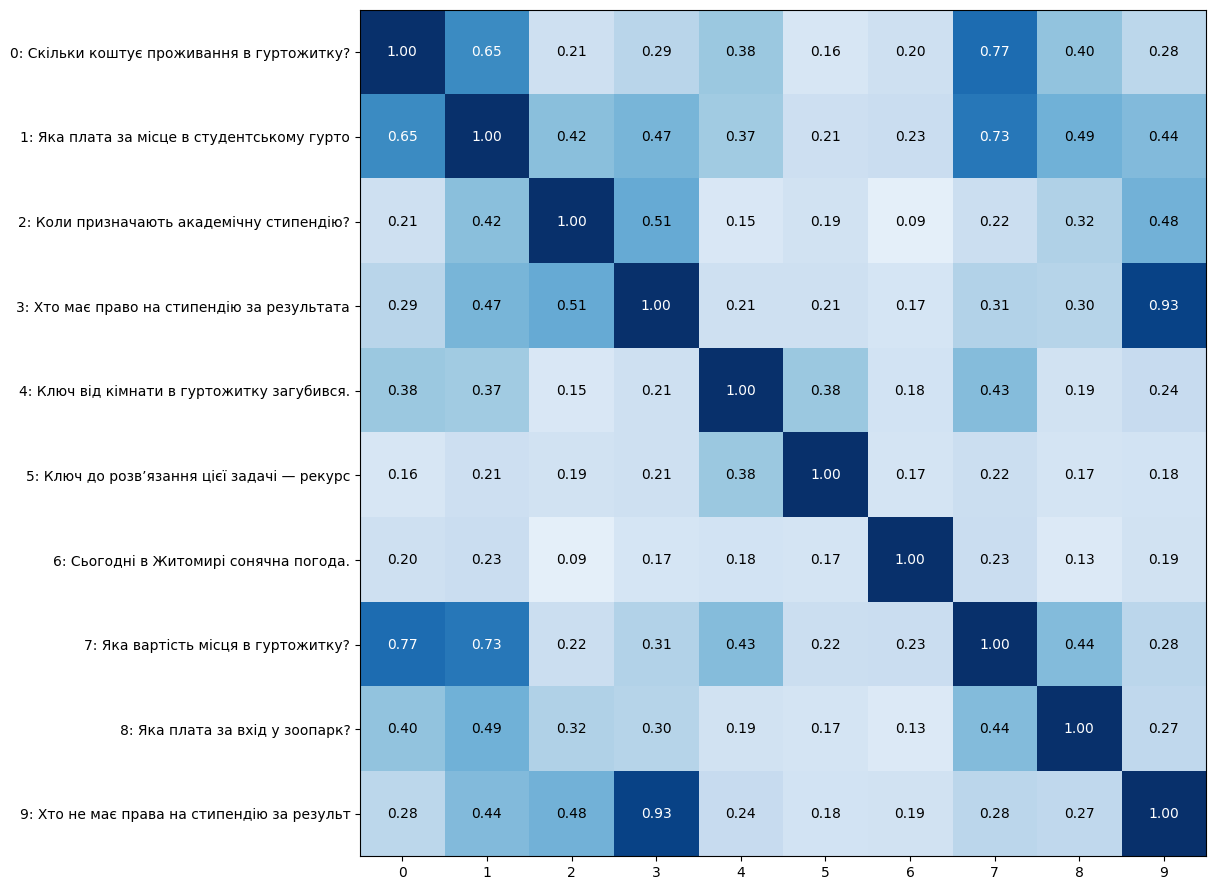

Перефразування 0 ↔ 7:          0.77   (для порівняння, 0 ↔ 1: 0.65)
Спільне слово 'плата' 1 ↔ 8:   0.49   (для порівняння, 1 ↔ 0: 0.65)
Заперечення 3 ↔ 9:             0.93   (для порівняння, 3 ↔ 2: 0.51)


In [27]:
# Питання 5: додаємо три власні речення до матриці з розділу 4
extra_sentences = [
    "Яка вартість місця в гуртожитку?",                   # 7: перефразування речення 0
    "Яка плата за вхід у зоопарк?",                       # 8: спільне слово «плата» з реченням 1, інший зміст
    "Хто не має права на стипендію за результатами сесії?",  # 9: заперечення речення 3
]
all_sentences = uni_sentences + extra_sentences
show_similarity_matrix(all_sentences, figsize=(12, 9))

emb = model.encode(all_sentences, normalize_embeddings=True).astype(np.float32)
sim = emb @ emb.T
print(f"Перефразування 0 ↔ 7:          {sim[0, 7]:.2f}   (для порівняння, 0 ↔ 1: {sim[0, 1]:.2f})")
print(f"Спільне слово 'плата' 1 ↔ 8:   {sim[1, 8]:.2f}   (для порівняння, 1 ↔ 0: {sim[1, 0]:.2f})")
print(f"Заперечення 3 ↔ 9:             {sim[3, 9]:.2f}   (для порівняння, 3 ↔ 2: {sim[3, 2]:.2f})")

### Питання 6
Яким чином модель Qwen/Qwen3-Embedding-0.6B саботує проведення dance-battle в "Житомирській політехніці"? Як думаєте, чи зможете Ви підібрати ембедингову модель, яка буде притримуватися іншої думки?

**Відповідь:** **Як «саботує».** У матриці розділу 4 фраза «Танцюльки на денс-батлі» має з «Піти на перездачу» подібність **0,67**, а з «Отримати гарну оцінку з СШІ» лише **0,39**. Тобто в просторі ембедингів Qwen3 денс-батл стоїть **значно ближче до перездачі (провалу), ніж до гарної оцінки** — за цією моделлю такі танцюльки асоціюються з відставанням у навчанні, а не з успіхом. Для порівняння, 0,67 — це рівень подібності, як у перефразувань із розділу 4 (0,65). Якби довірити цій моделі вибір («що з цього пов'язане з денс-батлом?»), вона б відповіла «перездача» і проголосувала б проти денс-батлу.

**Чи можна підібрати модель з іншою думкою?** Я перевірив ще п'ять моделей ембедингів (результати в клітинці вище):

| модель | денс-батл ↔ гарна оцінка | денс-батл ↔ перездача |
|---|---|---|
| Qwen3-Embedding-0.6B | 0,39 | 0,67 |
| paraphrase-multilingual-MiniLM-L12-v2 | 0,07 | 0,50 |
| multilingual-e5-small | 0,85 | 0,89 |
| multilingual-e5-base | 0,84 | 0,88 |
| LaBSE | 0,02 | 0,26 |
| BAAI/bge-m3 | 0,34 | 0,42 |

Жодна з шести не змінила «думку»: перездача завжди ближче, ніж гарна оцінка. У e5 різниця мінімальна (0,04), тобто фактично нічия, і така модель «нейтральна». Причина, ймовірно, не в упередженості однієї моделі: «Танцюльки на денс-батлі» та «Піти на перездачу» — схожі за формою короткі фрази про студентську активність/подію (дія, а не результат), а «Отримати гарну оцінку» — результат. Тому змусити модель «підтримати денс-батл» у такому формулюванні мені не вдалося.

Важливі зауваження: (1) абсолютні числа різних моделей порівнювати не можна (e5 має всі значення в межах 0,85–0,9, LaBSE — 0,02–0,26), порівнювати можна лише порядок; (2) результат залежить від точного формулювання коротких фраз: зі зміною слів порядок цілком може змінитися, тому я думаю, що модель з протилежною думкою знайти можна, просто змінивши формулювання або перебравши більше моделей; (3) такі «думки» — це лише асоціації, виведені з тренувальних даних, а не оцінка реальної користі денс-батлу, тож робити за ними висновки не варто.

In [36]:
# Питання 6: значення Qwen3 для трьох фраз із розділу 4 і порівняння з іншими моделями
labels_short = ["денс-батл", "гарна оцінка", "перездача"]
emb = model.encode(pseudo_random_sentences, normalize_embeddings=True).astype(np.float32)
sim = emb @ emb.T
print(f"{'Qwen/Qwen3-Embedding-0.6B':58s} денс-батл↔гарна оцінка = {sim[0, 1]:.2f} | денс-батл↔перездача = {sim[0, 2]:.2f}")

for name, prefix in [("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", ""),
                     ("intfloat/multilingual-e5-small", "query: "),
                     ("intfloat/multilingual-e5-base", "query: "),
                     ("sentence-transformers/LaBSE", ""),
                     ("BAAI/bge-m3", "")]:
    other = SentenceTransformer(name, device=device)
    e = other.encode([prefix + s for s in pseudo_random_sentences], normalize_embeddings=True)
    s = e @ e.T
    verdict = "перездача ближче" if s[0, 2] > s[0, 1] else "гарна оцінка ближче"
    print(f"{name:58s} денс-батл↔гарна оцінка = {s[0, 1]:.2f} | денс-батл↔перездача = {s[0, 2]:.2f} -> {verdict}")
    del other
torch.cuda.empty_cache()

Qwen/Qwen3-Embedding-0.6B                                  денс-батл↔гарна оцінка = 0.39 | денс-батл↔перездача = 0.67


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 денс-батл↔гарна оцінка = 0.07 | денс-батл↔перездача = 0.50 -> перездача ближче


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

intfloat/multilingual-e5-small                             денс-батл↔гарна оцінка = 0.85 | денс-батл↔перездача = 0.89 -> перездача ближче


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

... (41 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

BAAI/bge-m3                                                денс-батл↔гарна оцінка = 0.34 | денс-батл↔перездача = 0.42 -> перездача ближче


### Питання 7
У розділі 5 «Тексти на площині» ембединги проєктують на площину методом головних компонент (PCA). Чому речення однієї теми групуються разом, хоча проєкція втрачає більшу частину інформації? Чи можна за відстанню між точками на графіку судити про справжню подібність текстів?

**Відповідь:** Ембединг має 1024 виміри, PCA залишає лише 2 напрямки з найбільшою дисперсією: у цьому прикладі PC1 і PC2 разом пояснюють лише ≈27% (0,14 + 0,13) дисперсії, тобто ≈73% інформації втрачено. Але групи все одно видно, бо **тема — це найсильніший чинник відмінностей між цими реченнями**: PCA шукає саме напрямки, вздовж яких тексти розрізняються найбільше, і тому вони здебільшого збігаються з відмінностями між темами (гуртожиток, стипендія, оцінювання, «інше»). Середня косинусна подібність у межах однієї теми 0,40 проти 0,22 між різними темами, тож розділення в повному просторі існує, і дві компоненти його частково відображають.

Але **за відстанню між точками на графіку про справжню подібність судити не можна**: кореляція між відстанню на площині та справжньою косинусною подібністю лише −0,51 (для ідеальної проєкції вона була б близька до −1). Дві точки, які поруч на площині, можуть бути далеко одна від одної в решті 1022 вимірів, і навпаки. Осі не мають змісту, а картинка залежить від набору текстів, які ми проєктуємо. Графік добре підходить для інтуїції («тексти однієї теми схожі»), але рішення (наприклад, пошук) ухвалюють за косинусом у повному просторі.

In [33]:
# Питання 7: скільки інформації залишається після проєкції на 2 компоненти і наскільки відстані на площині відповідають справжній подібності
_, S, _ = np.linalg.svd(centered, full_matrices=False)
explained = S ** 2 / np.sum(S ** 2)
print("Частка дисперсії PC1 і PC2:", np.round(explained[:2], 3), "| разом:", round(float(explained[:2].sum()), 3))

full_sim = points @ points.T
dist_2d = np.linalg.norm(xy[:, None] - xy[None], axis=-1)
iu = np.triu_indices(len(points), 1)
print("Кореляція «відстань на площині» ↔ «косинусна подібність»:", round(float(np.corrcoef(dist_2d[iu], full_sim[iu])[0, 1]), 2))

labels_arr = np.array(labels)
same_topic = (labels_arr[:, None] == labels_arr[None])[iu]
print("Середня косинусна подібність у межах однієї теми:", round(float(full_sim[iu][same_topic].mean()), 2))
print("Середня косинусна подібність між різними темами: ", round(float(full_sim[iu][~same_topic].mean()), 2))

Частка дисперсії PC1 і PC2: [0.14 0.13] | разом: 0.274
Кореляція «відстань на площині» ↔ «косинусна подібність»: -0.51
Середня косинусна подібність у межах однієї теми: 0.4
Середня косинусна подібність між різними темами:  0.22


### Питання 8
Порівняйте дві матриці подібності в розділі 6 «Запит і документ кодуються по-різному». Що змінює інструкція, яку модель додає до запиту?

**Відповідь:** Без інструкції (`prompt_name=None`) запит кодується як звичайне речення; з інструкцією модель додає перед запитом текст `Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:` і кодує його як **пошуковий запит**, який шукає відповідь у фрагментах (документи, навпаки, кодуються без інструкції).

Що змінилося в матрицях (числа з клітинки вище):
- Подібність правильних пар (діагональ) зросла в усіх чотирьох запитів: 0,44→0,51, 0,69→0,76, 0,43→0,45, 0,38→0,40. Загалом значення в матриці трохи зсунулися вгору (наприклад, хибна пара «гуртожиток — тиша» 0,52→0,61), тож важливі не самі значення, а відрив правильної пари від найкращої хибної.
- Відрив (діагональ мінус найкращий хибний фрагмент) змінився неоднорідно: для запитів 2 і 4 він зріс (0,47→0,52 і 0,18→0,21), а для запитів 1 і 3 трохи зменшився (−0,08→−0,11 і 0,28→0,25). Середній відрив практично не змінився (≈0,21→≈0,22).
- Ранжування від інструкції не змінилося: запити 2, 3 і 4 знаходять свій фрагмент і без неї, а запит 1 («До якої дати платити за гуртожиток?») програє фрагменту про тишу в обох випадках, бо в правильному фрагменті немає слова «гуртожиток». Це виправляє лише назва документа (розділ 9).

Висновок: інструкція повідомляє моделі призначення тексту (пошуковий запит до фрагмента), з якою вона навчалась, і зазвичай трохи покращує пошук. Проте на чотирьох прикладах ефект малий і нестабільний, тож його треба вимірювати на бенчмарку, а не на 4 запитах.

In [30]:
# Питання 8: числові різниці між двома матрицями розділу 6 (без інструкції і з інструкцією)
q_plain = model.encode(queries, normalize_embeddings=True, prompt_name=None).astype(np.float32)
q_instr = model.encode(queries, normalize_embeddings=True, prompt_name="query").astype(np.float32)
p_emb = passage_embeddings.astype(np.float32)
mask = np.eye(4, dtype=bool)
for name, S in [("без інструкції", q_plain @ p_emb.T), ("з інструкцією", q_instr @ p_emb.T)]:
    diag = np.diag(S)
    best_wrong = np.where(mask, -1, S).max(axis=1)
    print(f"{name}: діагональ {np.round(diag, 2)} | відрив від найкращого хибного {np.round(diag - best_wrong, 2)}")

без інструкції: діагональ [0.44 0.69 0.43 0.38] | відрив від найкращого хибного [-0.08  0.47  0.28  0.18]
з інструкцією: діагональ [0.51 0.76 0.45 0.4 ] | відрив від найкращого хибного [-0.11  0.52  0.25  0.21]


### Питання 9
Поставте в розділі 8 «Пошук вручну» три власні питання до документів університету. Чи потрапив правильний документ до трьох найближчих фрагментів? Порівняйте подібність найкращого фрагмента з подібністю для питання, на яке в документах немає відповіді.

**Відповідь:** Мої питання та результати (див. клітинку вище):
- «Хто може бути старостою академічної групи?» — ✓ усі три найближчі фрагменти з правильного документа №336, найкраща подібність 0,71;
- «За що призначається стипендія ректора?» — ✓ документ №344 на 1-й і 3-й позиції, подібність 0,70;
- «Як студент може оскаржити оцінку?» — ✗ правильний документ №275 (Положення про оцінювання) у трійку не потрапив; знайдено Кодекс академічної доброчесності (№1199) і правила стипендій (№340), подібності 0,57/0,53/0,52. Ймовірна причина: у положенні процедуру названо інакше (апеляція, незгода з оцінкою), а слово «оскаржити» ближче до тексту кодексу про порушення; формулювання з демо («Що робити, якщо я не згоден з оцінкою…») знаходить правильний документ.

**Питання без відповіді:** «Яка погода буде завтра в Житомирі?» — найкраща подібність 0,44; «Скільки коштує обід у студентській їдальні?» — 0,51 (фрагменти про оплату гуртожитку). Тобто для питань без відповіді найкращий фрагмент має 0,44–0,51 проти 0,57–0,71 для питань із відповіддю, значення справді нижчі, але діапазони близькі, а слабка «правильна» знахідка (0,57) лише трохи вища за «хибну» (0,51). Універсального порогу не існує: поріг ≈0,5 тут відсікав би питання без відповіді, але водночас губив би частину правильних відповідей на інших питаннях. Тому відмову варто доручати не лише порогу, а й генеративній моделі та/або переранжувачу.

In [31]:
# Питання 9: три власні питання + питання без відповіді
my_questions = [
    ("Хто може бути старостою академічної групи?", "336"),
    ("За що призначається стипендія ректора?", "344"),
    ("Як студент може оскаржити оцінку?", "275"),
    ("Яка погода буде завтра в Житомирі?", None),
    ("Скільки коштує обід у студентській їдальні?", None),
]
for q, gold in my_questions:
    res = search(q, chunk_embeddings, k=3)
    docs = [chunks[i]["doc_id"] for i, _ in res]
    mark = "—" if gold is None else ("✓" if gold in docs else "✗")
    print(f"{mark} {q}\n    очікуємо: {gold} | топ-3 документи: {docs} | подібності: {[round(s, 2) for _, s in res]}")

✓ Хто може бути старостою академічної групи?
    очікуємо: 336 | топ-3 документи: ['336', '336', '336'] | подібності: [0.71, 0.66, 0.59]
✓ За що призначається стипендія ректора?
    очікуємо: 344 | топ-3 документи: ['344', '340', '344'] | подібності: [0.7, 0.68, 0.6]
✗ Як студент може оскаржити оцінку?
    очікуємо: 275 | топ-3 документи: ['1199', '340', '1199'] | подібності: [0.57, 0.53, 0.52]
— Яка погода буде завтра в Житомирі?
    очікуємо: None | топ-3 документи: ['275', '340', '1199'] | подібності: [0.44, 0.44, 0.42]
— Скільки коштує обід у студентській їдальні?
    очікуємо: None | топ-3 документи: ['348', '348', '340'] | подібності: [0.51, 0.48, 0.45]


### Питання 10
Чому дописування назви документа на початок фрагмента (розділ 9) покращує пошук? Знайдіть приклад фрагмента, який без назви документа втрачає зміст.

**Відповідь:** Фрагмент — це шматок тексту, вирваний з документа: він не містить заголовка і сусідніх фрагментів, тож ембединг відображає лише те, що в ньому написано. Назва документа на початку додає в текст ключові слова й тему, за якими користувач шукатиме («гуртожиток», «стипендія»), тому вектор фрагмента зсувається ближче до відповідних запитів; назва також допомагає відрізняти схожі документи між собою.

**Приклади.** (1) З розділу 6: фрагмент «Студент вносить авансовий платіж за 1 семестр до 1 вересня…» не містить слова «гуртожиток», тому для запиту «До якої дати платити за гуртожиток?» він отримував лише 0,51 і програвав фрагменту про тишу (0,61); з назвою «Положення про користування гуртожитками» подібність зросла до 0,76. (2) Реальний фрагмент №145 з документа про гуртожитки — це перелік категорій осіб («…студентам-дітям, один з батьків яких загинув…»): без назви незрозуміло, що це перелік пільговиків на поселення. Для запиту «Хто має першочергове право на поселення в гуртожиток?» подібність зросла з 0,31 до 0,51, а позиція — з 46-ї до 34-ї серед 361 фрагмента; для запиту «Які категорії студентів мають пільги при поселенні в гуртожиток?» — з 0,42 (51-ше місце) до 0,61 (25-те). Зверніть увагу: позиція все одно не в топ-3, тож назва допомагає лише частково, але прямо показує, що без неї фрагмент губить зміст.

In [35]:
# Питання 10: фрагмент, який без назви документа втрачає зміст
idx = 145
print("Назва документа:", documents[chunks[idx]["doc_id"]]["title"])
print("Фрагмент:", chunks[idx]["text"][:600], "…")
print()

def rank_and_score(question, embeddings, i):
    q = model.encode(question, normalize_embeddings=True, prompt_name="query").astype(np.float32)
    scores = embeddings.astype(np.float32) @ q
    return int((scores > scores[i]).sum()) + 1, round(float(scores[i]), 2)

for question in ["Хто має першочергове право на поселення в гуртожиток?",
                 "Які категорії студентів мають пільги при поселенні в гуртожиток?"]:
    print(question)
    print("   без назви документа (позиція у рейтингу з", len(chunks), "фрагментів, подібність):", rank_and_score(question, chunk_embeddings, idx))
    print("   з назвою документа  (позиція у рейтингу, подібність):", rank_and_score(question, titled_embeddings, idx))

Назва документа: Положення про користування гуртожитками
Фрагмент: о Закону України “Про статус ветеранів війни, гарантії їх соціального захисту”, та студентам-дітям таких категорій осіб; - студентам-дітям, один з батьків яких загинув (пропав безвісти) у районі проведення антитерористичної операції, здійснення заходів із забезпечення національної безпеки і оборони, відсічі і стримування збройної агресії Російської Федерації у Донецькій та Луганській областях, бойових дій чи збройних конфліктів або помер внаслідок поранення, контузії чи каліцтва, одержаних у районі проведення антитерористичної операції, здійснення заходів із забезпечення національної безпеки і …

Хто має першочергове право на поселення в гуртожиток?
   без назви документа (позиція у рейтингу з 361 фрагментів, подібність): (46, 0.31)
   з назвою документа  (позиція у рейтингу, подібність): (34, 0.51)
Які категорії студентів мають пільги при поселенні в гуртожиток?
   без назви документа (позиція у рейтингу з 361 фрагмент